# Lorenz System: Deterministic Chaos

The Lorenz system is a set of three ordinary differential equations:

$$\dot x=\sigma(y-x),\qquad \dot y=x(\rho-z)-y,\qquad \dot z=xy-\beta z.$$

With the classic parameters $\sigma=10$, $\rho=28$, $\beta=8/3$ the solutions never settle down and never repeat, yet they stay on a bounded set — the strange attractor.

This notebook uses SciPy to integrate the equations, NumPy for analysis, and Matplotlib for visualization.

## Import Libraries and Set Up the Problem

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

sigma, rho, beta = 10.0, 28.0, 8.0 / 3.0

def lorenz(t, state, sigma=sigma, rho=rho, beta=beta):
    x, y, z = state
    return [sigma * (y - x), x * (rho - z) - y, x * y - beta * z]

t_start, t_end = 0.0, 40.0
t_eval = np.linspace(t_start, t_end, 20000)
initial_state = np.array([1.0, 1.0, 1.0])

print(f"sigma = {sigma}, rho = {rho}, beta = {beta:.4f}")
print("Initial state:", initial_state)

sigma = 10.0, rho = 28.0, beta = 2.6667
Initial state: [1. 1. 1.]


## Fixed Points

Setting the right-hand side to zero gives the origin and, for $\rho>1$, two symmetric points

$$C_\pm=\left(\pm\sqrt{\beta(\rho-1)},\ \pm\sqrt{\beta(\rho-1)},\ \rho-1\right).$$

The trajectory spirals around $C_+$ and $C_-$, jumping between them unpredictably.

In [2]:
c = np.sqrt(beta * (rho - 1))
fixed_points = {
    "origin": np.array([0.0, 0.0, 0.0]),
    "C+": np.array([c, c, rho - 1]),
    "C-": np.array([-c, -c, rho - 1]),
}

for name, point in fixed_points.items():
    residual = np.linalg.norm(lorenz(0.0, point))
    print(f"{name:>6}: {np.round(point, 4)}, |f| = {residual:.2e}")

origin: [0. 0. 0.], |f| = 0.00e+00
    C+: [ 8.4853  8.4853 27.    ], |f| = 1.42e-14
    C-: [-8.4853 -8.4853 27.    ], |f| = 1.42e-14


## Integrate the Trajectory

We use an adaptive Runge–Kutta method with tight tolerances, since chaotic systems amplify numerical errors.

In [3]:
solution = solve_ivp(
    lorenz, (t_start, t_end), initial_state,
    t_eval=t_eval, method="RK45", rtol=1e-10, atol=1e-12,
)
x, y, z = solution.y

print("Success:", solution.success)
print("Final state:", np.round(solution.y[:, -1], 4))

Success: True
Final state: [-1.4251 -2.9456  3.6378]


## The Strange Attractor

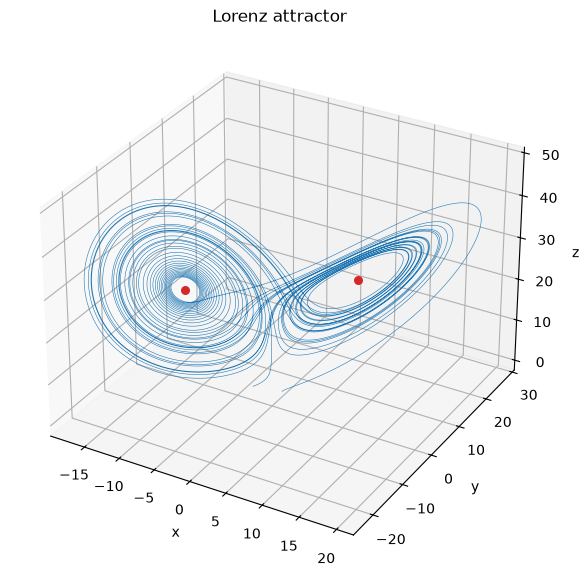

In [4]:
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(projection="3d")
ax.plot(x, y, z, lw=0.4, color="tab:blue")
for name in ("C+", "C-"):
    ax.scatter(*fixed_points[name], color="tab:red", s=30)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Lorenz attractor")
plt.show()

## Sensitivity to Initial Conditions

Two trajectories starting $10^{-8}$ apart stay together for a while, then diverge completely. This is the "butterfly effect".

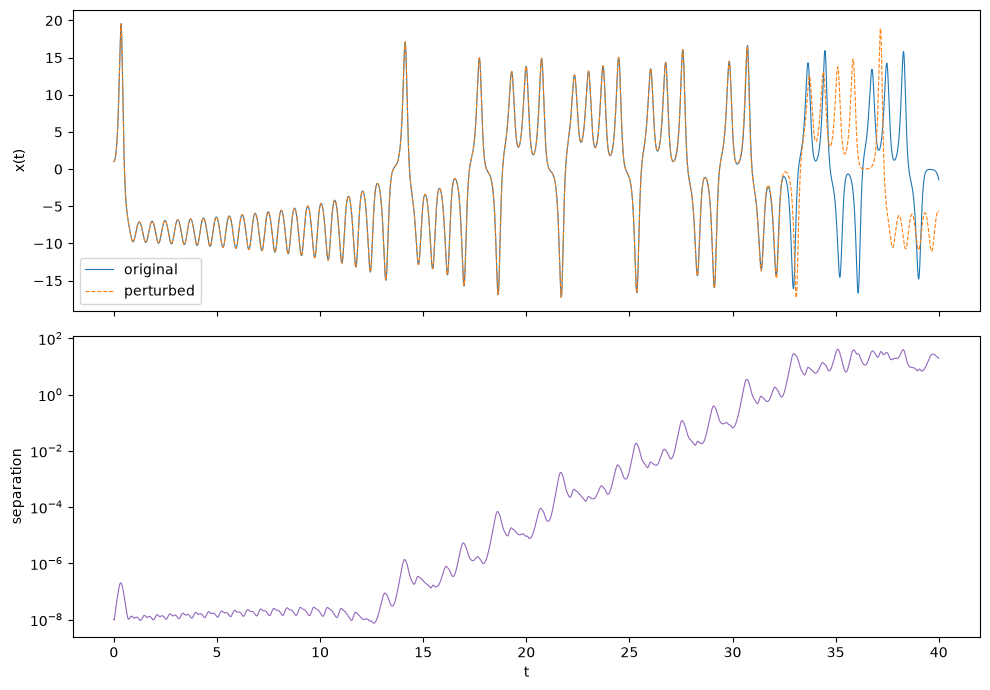

In [5]:
delta0 = 1e-8
perturbed_state = initial_state + np.array([delta0, 0.0, 0.0])

perturbed = solve_ivp(
    lorenz, (t_start, t_end), perturbed_state,
    t_eval=t_eval, method="RK45", rtol=1e-10, atol=1e-12,
)
separation = np.linalg.norm(solution.y - perturbed.y, axis=0)

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(t_eval, x, label="original", lw=0.8)
axes[0].plot(t_eval, perturbed.y[0], label="perturbed", lw=0.8, ls="--")
axes[0].set_ylabel("x(t)")
axes[0].legend()

axes[1].semilogy(t_eval, separation, color="tab:purple", lw=0.8)
axes[1].set_xlabel("t")
axes[1].set_ylabel("separation")
plt.tight_layout()
plt.show()

## Estimating the Largest Lyapunov Exponent

During the growth phase the separation behaves like $\delta(t)\approx\delta_0 e^{\lambda t}$. A linear fit of $\ln\delta(t)$ gives $\lambda$; the accepted value is $\lambda\approx 0.906$.

In [6]:
growth = (separation > 10 * delta0) & (separation < 1.0)
slope, intercept = np.polyfit(t_eval[growth], np.log(separation[growth]), 1)

print(f"Estimated largest Lyapunov exponent: {slope:.3f}")
print("Reference value: ~0.906")

Estimated largest Lyapunov exponent: 0.774
Reference value: ~0.906


## Benettin Method

A single fit is rough. A more reliable estimate follows a nearby trajectory, renormalizes the separation back to $\delta_0$ at fixed intervals, and averages the logarithmic growth rates.

In [7]:
def lyapunov_benettin(state, delta0=1e-8, dt=0.5, n_steps=400, transient=10.0):
    state = solve_ivp(lorenz, (0, transient), state, rtol=1e-10, atol=1e-12).y[:, -1]
    neighbor = state + np.array([delta0, 0.0, 0.0])
    log_sum = 0.0
    for _ in range(n_steps):
        state = solve_ivp(lorenz, (0, dt), state, rtol=1e-10, atol=1e-12).y[:, -1]
        neighbor = solve_ivp(lorenz, (0, dt), neighbor, rtol=1e-10, atol=1e-12).y[:, -1]
        d = np.linalg.norm(neighbor - state)
        log_sum += np.log(d / delta0)
        neighbor = state + (neighbor - state) * (delta0 / d)
    return log_sum / (n_steps * dt)

lam = lyapunov_benettin(initial_state)
print(f"Largest Lyapunov exponent (Benettin): {lam:.3f}")

Largest Lyapunov exponent (Benettin): 0.912


## Ensemble Average over 250 Initial Conditions

A single pair of trajectories gives a noisy growth curve, because the local stretching rate varies across the attractor. Here we average over many pairs instead:

- **Starting points** are taken *on* the attractor: one long trajectory with the first 50 time units dropped, sampled every 2 time units (much longer than the decorrelation time /\lambda$), so the starts are effectively independent and cover the attractor with its natural density.
- **Perturbations** have size $\delta_0=10^{-10}$ in a random direction, which gives a long linear range before the separation saturates.
- The runs are spread across all CPU cores with `joblib`.

Since $\lambda=\lim_{t\to\infty}\frac{1}{t}\langle\ln(\delta(t)/\delta_0)\rangle$, we average the **logarithm** of the separation (not the separation itself) and fit a line to it. The error bar comes from bootstrapping over trajectories.

250 runs in 21.6 s
Ensemble Lyapunov exponent: 0.907 ± 0.003
Fit window: t in [2.0, 20.4]
Reference value: ~0.906


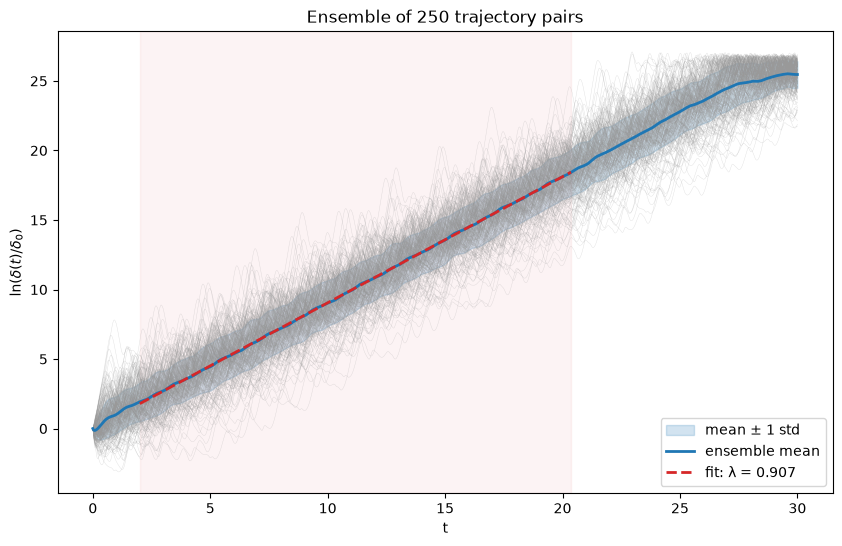

In [8]:
import time
from joblib import Parallel, delayed

n_runs = 250
ens_delta0 = 1e-10
ens_T = 30.0
ens_t = np.linspace(0.0, ens_T, 3001)

# Starting points sampled on the attractor: one long trajectory with the transient
# dropped, sampled every 2 time units so the starts are effectively independent.
spacing, transient = 2.0, 50.0
sample_times = transient + spacing * np.arange(n_runs)
reference = solve_ivp(
    lorenz, (0.0, sample_times[-1]), initial_state,
    t_eval=sample_times, rtol=1e-10, atol=1e-12,
)
starts = reference.y.T

rng = np.random.default_rng(0)
directions = rng.normal(size=(n_runs, 3))
directions /= np.linalg.norm(directions, axis=1, keepdims=True)

def pair_rhs(t, s):
    return lorenz(t, s[:3]) + lorenz(t, s[3:])

def log_separation(start, direction):
    # Integrate both trajectories as one 6D system so they share the same time steps.
    pair = np.concatenate([start, start + ens_delta0 * direction])
    sol = solve_ivp(pair_rhs, (0.0, ens_T), pair, t_eval=ens_t, rtol=1e-12, atol=1e-14)
    return np.log(np.linalg.norm(sol.y[3:] - sol.y[:3], axis=0) / ens_delta0)

tic = time.perf_counter()
log_seps = np.array(Parallel(n_jobs=-1)(
    delayed(log_separation)(s, d) for s, d in zip(starts, directions)
))
print(f"{n_runs} runs in {time.perf_counter() - tic:.1f} s")

mean_log = log_seps.mean(axis=0)
std_log = log_seps.std(axis=0)

# Fit window: after the perturbation aligns with the unstable direction (t >= 2)
# and before the separation reaches the size of the attractor (delta < 1e-2).
fit = (ens_t >= 2.0) & (np.log(ens_delta0) + mean_log < np.log(1e-2))
lam_ens, b_ens = np.polyfit(ens_t[fit], mean_log[fit], 1)

boot = [
    np.polyfit(ens_t[fit], log_seps[rng.integers(0, n_runs, n_runs)].mean(axis=0)[fit], 1)[0]
    for _ in range(1000)
]
print(f"Ensemble Lyapunov exponent: {lam_ens:.3f} ± {np.std(boot):.3f}")
print(f"Fit window: t in [{ens_t[fit][0]:.1f}, {ens_t[fit][-1]:.1f}]")
print("Reference value: ~0.906")

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(ens_t, log_seps.T, color="0.6", lw=0.3, alpha=0.3)
ax.fill_between(ens_t, mean_log - std_log, mean_log + std_log, color="tab:blue", alpha=0.2, label="mean ± 1 std")
ax.plot(ens_t, mean_log, color="tab:blue", lw=2, label="ensemble mean")
ax.plot(ens_t[fit], lam_ens * ens_t[fit] + b_ens, color="tab:red", ls="--", lw=2,
        label=f"fit: λ = {lam_ens:.3f}")
ax.axvspan(ens_t[fit][0], ens_t[fit][-1], color="tab:red", alpha=0.05)
ax.set_xlabel("t")
ax.set_ylabel(r"$\ln(\delta(t)/\delta_0)$")
ax.set_title(f"Ensemble of {n_runs} trajectory pairs")
ax.legend()
plt.show()

## Conclusion

The Lorenz equations are fully deterministic, yet a positive Lyapunov exponent means tiny differences in initial conditions grow exponentially. Long-term prediction is impossible in practice, even though the motion stays on a bounded attractor.